<a href="https://colab.research.google.com/github/asrevo-applied-ml/basic-ml/blob/main/classifications.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Classification

### Import Libs

In [61]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from math import sqrt
from sklearn.metrics import accuracy_score,confusion_matrix,precision_score,recall_score,f1_score,precision_recall_curve,roc_curve,roc_auc_score
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import SGDClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.model_selection import cross_val_score,cross_val_predict
from sklearn.metrics import ConfusionMatrixDisplay


### load dataset

In [2]:
# from sklearn.datasets import fetch_openml
# d=fetch_openml('mnist_784', version=1, as_frame=False, parser='auto')


import numpy as np
from sklearn.utils import Bunch
from tensorflow.keras.datasets import mnist

(X_tr, y_tr), (X_te, y_te) = mnist.load_data()
d = Bunch(
    data=np.concatenate([X_tr, X_te]).reshape(-1, 784).astype('float64'),
    target=np.concatenate([y_tr, y_te]).astype(str).astype(object),
    categories={'class': [str(i) for i in range(10)]},
)

In [3]:
data,target,categories=d["data"],d["target"],d["categories"]["class"]

In [4]:
data.shape

(70000, 784)

In [5]:
target.shape

(70000,)

In [6]:
categories

['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']

## EDA

In [7]:
def show_img(img_data):
  mn=img_data.shape[0]
  m=int(sqrt(mn))
  number=img_data.reshape((m,m))
  plt.imshow(number,cmap="binary")


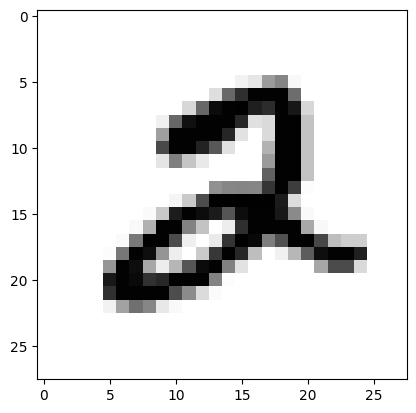

In [8]:
show_img(data[5])

### split the data

In [9]:
x_train,y_train,x_test,y_test=data[:60000],target[:60000],data[60000:],target[60000:]

# tag the target as is 5 or not

In [10]:
y_train_5=y_train=='5'
y_test_5=y_test=='5'

try Dummy classifier accuricy

### hint a dummy classifier getting a a percentage of accuracy 9/10  

In [11]:
cross_val_score(DummyClassifier(),x_train,y_train_5,cv=3,scoring="accuracy")

array([0.90965, 0.90965, 0.90965])

SDG classifier

#### **accurcy** percent of correct vs wrong predictions

In [12]:
cross_val_score(SGDClassifier(random_state=42),x_train,y_train_5,cv=3,scoring="accuracy")

array([0.95035, 0.96035, 0.9604 ])

In [13]:
y_train_predict=cross_val_predict(SGDClassifier(random_state=42),x_train,y_train_5,cv=3)

### *confixan matrix*

In [14]:
confusion_matrix(y_train_5,y_train_predict)

array([[53892,   687],
       [ 1891,  3530]])

##  **recal** *TPR* percent of correct predict of true of all true class
### 3430/3530+1891

In [15]:
recall_score(y_train_5,y_train_predict)

0.6511713705958311

### **65%** of all images that has 5 i was able to predict it and classify them as 5

## **Precission**. from all true predication we did , what is the  correct percentage
### 3530/3530+687



In [16]:
precision_score(y_train_5,y_train_predict)

0.8370879772350012

### **F1 score** harmonic mean that claculate average and give high wight to small values ( **recall** , **percission** )

In [17]:
f1_score(y_train_5,y_train_predict)

0.7325171197343847

## **Precission vs Recall** trade off

In [18]:
y_train_predict=cross_val_predict(SGDClassifier(random_state=42),x_train,y_train_5,cv=3)

In [19]:
confusion_matrix(y_train_5,y_train_predict)

array([[53892,   687],
       [ 1891,  3530]])

In [20]:
print(f"precision = {precision_score(y_train_5,y_train_predict)} , recall = {recall_score(y_train_5,y_train_predict)} , f_score = {f1_score(y_train_5,y_train_predict)}")


precision = 0.8370879772350012 , recall = 0.6511713705958311 , f_score = 0.7325171197343847


In [21]:
cls=SGDClassifier(random_state=42)
cls.fit(x_train,y_train_5)


SGDClassifier(random_state=42)

In [22]:
y_score=cls.decision_function([x_train[0]])  # get probability
y_score

array([2164.22030239])

In [23]:
threshold=0

In [24]:
y_score>threshold

array([ True])

In [25]:
threshold=3000
y_score>threshold


array([False])

In [26]:
y_scores=cross_val_predict(SGDClassifier(random_state=42),x_train,y_train_5,cv=3,method="decision_function")

In [27]:
precisions,recalls,thresholds=precision_recall_curve(y_train_5,y_scores)

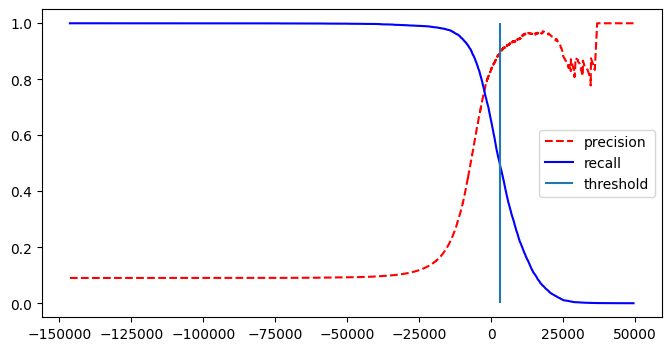

In [28]:
plt.figure(figsize=(8, 4))
plt.plot(thresholds,precisions[:-1],color="red",linestyle="--",label="precision")
plt.plot(thresholds,recalls[:-1],color="blue",linestyle="-",label="recall")
plt.vlines(threshold,0,1,label="threshold")
plt.legend(loc="center right")
plt.show()

In [29]:
max_precision_idx=(precisions>=.9).argmax()
precisions[max_precision_idx],recalls[max_precision_idx],thresholds[max_precision_idx]

(np.float64(0.9000345901072293),
 np.float64(0.4799852425751706),
 np.float64(3370.0194991439557))

# Multiclass classification

In [30]:
clf=SVC()
clf.fit(x_train[:2000],y_train[:2000])

SVC()

In [31]:
clf.predict([x_train[0]])

array(['5'], dtype=object)

In [34]:
decisions=clf.decision_function([x_train[0]])
decisions

array([[ 3.79297828,  0.72949369,  6.06184129,  8.29800527, -0.29383983,
         9.30157597,  1.74723215,  2.77365456,  7.20601456,  4.82245092]])

In [33]:
clf.classes_

array(['0', '1', '2', '3', '4', '5', '6', '7', '8', '9'], dtype=object)

In [38]:
print(f"class {clf.classes_[decisions.argmax()]}")

class 5


In [67]:
y_train_predict_2000=cross_val_predict(SGDClassifier(random_state=42),x_train,y_train,cv=3)


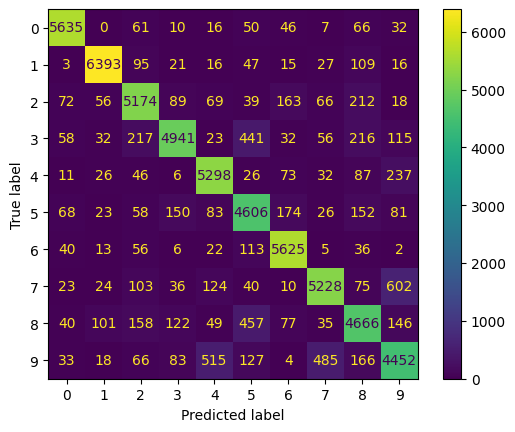

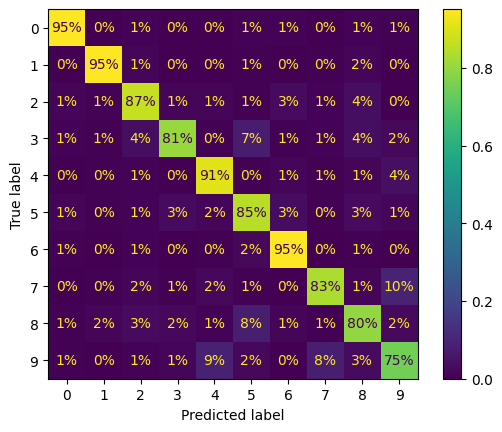

In [72]:
ConfusionMatrixDisplay.from_predictions(y_train,y_train_predict_2000)
ConfusionMatrixDisplay.from_predictions(y_train,y_train_predict_2000,normalize="true",values_format=".0%")



In [62]:
from sklearn.multiclass import  OneVsRestClassifier


ovr_cls=OneVsRestClassifier(SVC(random_state=42))
ovr_cls.fit(x_train[:2000],y_train[:2000])
ovr_cls.classes_



array(['0', '1', '2', '3', '4', '5', '6', '7', '8', '9'], dtype='<U1')

In [48]:
ovr_cls.decision_function([x_train[0]])

array([[-1.32802451, -1.79073853, -1.39262214, -0.94416346, -2.29003973,
         0.80921042, -1.72304481, -1.20954271, -1.63739176, -1.79246052]])

In [50]:
from sklearn.multiclass import  OneVsOneClassifier


ovo_cls=OneVsOneClassifier(SVC(random_state=42))
ovo_cls.fit(x_train[:2000],y_train[:2000])
ovo_cls.classes_



array(['0', '1', '2', '3', '4', '5', '6', '7', '8', '9'], dtype=object)

In [51]:
ovo_cls.decision_function([x_train[0]])


array([[ 3.79036372,  0.72982646,  6.0496505 ,  8.29824157, -0.29301871,
         9.30146432,  1.74642332,  2.77341303,  7.20451423,  4.81969169]])